# ゴルフボールを落として「重力の強さ」を測ろう（Python編）
### 新潟大学 創生学部　アソシエーションゼミ

- Excel 編（`自由落下_重力加速度推定_Excel解説.md`）の LINEST 関数でしたことを、Python でも行う
- 落ちる高さは時刻 t の二次関数：y = A + B t + C t²。重力加速度 g は **g = −2C**（y = 高さ0 − ½ g t² より）
- セルは**上から順番に**実行すること（`Shift + Enter` で実行して次のセルへ進む）

## 目次
- [1. 準備](#1.-準備)
- [2. 二次関数を当てはめて g を求める](#2.-二次関数を当てはめて-g-を求める)
- [3. g の標準誤差](#3.-g-の標準誤差)
- [4. 自分の実験データで求める](#4.-自分の実験データで求める)

## 1. 準備

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

from statsmodels.formula.api import ols


## 2. 二次関数を当てはめて g を求める

- ここでは、Tracker で記録したような値を乱数で作る（30 コマ/秒、0.5秒間、高さ1.5 m から。読み取りのぶれ 5 mm）
- `ols('h ~ t + I(t ** 2)', …)` で、高さ h を t と t² の式で表す（`I(t ** 2)` が t²）

Intercept    1.500682
t            0.012517
I(t ** 2)   -4.935365
dtype: float64
g = 9.87 m/s²、決定係数 0.9999


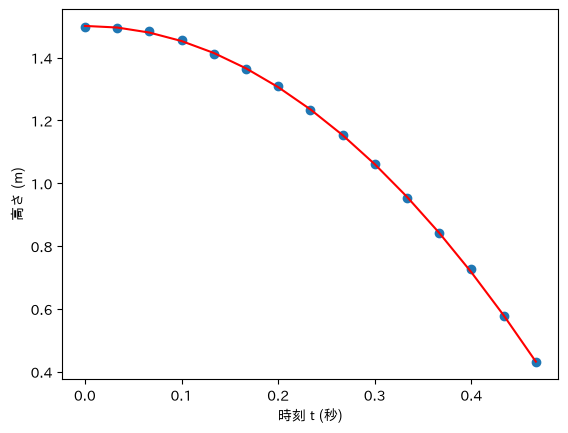

In [2]:
rng = np.random.default_rng(348309421)
t = np.arange(0, 0.5, 1 / 30)                                   # 30コマ/秒の時刻
h = 1.5 - 0.5 * 9.8 * t ** 2 + rng.normal(0, 0.005, len(t))     # 高さ（正解 g = 9.8）
df_fall = pd.DataFrame({'t': t, 'h': h})

res_fall = ols('h ~ t + I(t ** 2)', data=df_fall).fit()
print(res_fall.params)
C2 = res_fall.params['I(t ** 2)']
print(f'g = {-2 * C2:.2f} m/s²、決定係数 {res_fall.rsquared:.4f}')

plt.scatter(df_fall['t'], df_fall['h'], zorder=2)
plt.plot(df_fall['t'], res_fall.predict(), color='r', zorder=3)
plt.xlabel('時刻 t (秒)')
plt.ylabel('高さ (m)')
plt.show()

- `I(t ** 2)` の係数が C。`-2 * C2` で g が求まり、9.8 に近い値になる
- Excel では、散布図の「近似曲線の追加」→「多項式（次数 2）」→「グラフに数式を表示する」でも同じ式が出る。LINEST 関数を使う手順は Excel 編を参照
- t の係数 B は、手を離したときの速さ（0 に近い）
- 自分の実験データ（Tracker の t と y）を Excel で整えて読めば、同じコードで g が求まる


## 3. g の標準誤差

- 点にはばらつきがあるので、同じ実験を何度もくり返すと、C（と g）も毎回少しずつ変わる。そのばらつき（標準偏差）を、**1回のデータから見積もったもの**が**標準誤差**
- データの点のばらつき（読み取りのぶれ 5 mm）とは別のもの
- `res.bse` に、係数ごとの標準誤差が入っている（`res.params` と同じ並び）
- g = −2C は C を2倍して符号を変えただけなので、**g の標準誤差は C の標準誤差の2倍**
- `res.conf_int()` は係数の **95%信頼区間**（「正解はたぶんこの範囲」）。−2倍すると下限と上限が入れ替わる

In [3]:
print(res_fall.bse)                                   # [1] 係数ごとの標準誤差
se = res_fall.bse['I(t ** 2)']                         # C の標準誤差
print(f'g = {-2 * C2:.2f} ± {2 * se:.2f} m/s²')       # [2] g の標準誤差は2倍

lo, hi = res_fall.conf_int().loc['I(t ** 2)']          # [3] C の95%信頼区間
print(f'95%信頼区間：{-2 * hi:.2f} 〜 {-2 * lo:.2f} m/s²')


Intercept    0.002874
t            0.028586
I(t ** 2)    0.059075
dtype: float64
g = 9.87 ± 0.12 m/s²
95%信頼区間：9.61 〜 10.13 m/s²


- 正解の 9.8 は、95%信頼区間の中に入っている
- Excel の `=LINEST(高さ, 時刻^{1,2}, TRUE, TRUE)` の**2行目**が標準誤差で、`res.bse` と同じ値になる。ただし Excel は並びが逆（左から t² の係数、t の係数、切片）
- 点を増やす（`0.5` を `1` にして1秒間にする）、読み取りのぶれを小さくする（`0.005` を `0.001` に）と、標準誤差は小さくなる
- この標準誤差は、高さの読み取りのぶれだけを考えたもの。時刻のずれ（コマ落ちなど）は入っていない


## 4. 自分の実験データで求める

- Tracker の t と y を Excel に貼り、1行目を列名 `t`・`h` にして保存する（例：`fall.xlsx`）
- notebook と同じ場所に置き、下のセルの `#` を外して実行する。そのあと 2・3 のセルを、`df_fall` を作る行を除いて実行すれば g ± 標準誤差が求まる

In [4]:
# df_fall = pd.read_excel('fall.xlsx')
# df_fall
